In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import pandas as pd
from matplotlib.colors import ListedColormap

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Scikit-learn Modelleri
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

In [54]:
iris = load_iris()
iris.feature_names
a=iris.DESCR

X_full = iris.data
y_full = iris.target
print(a)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

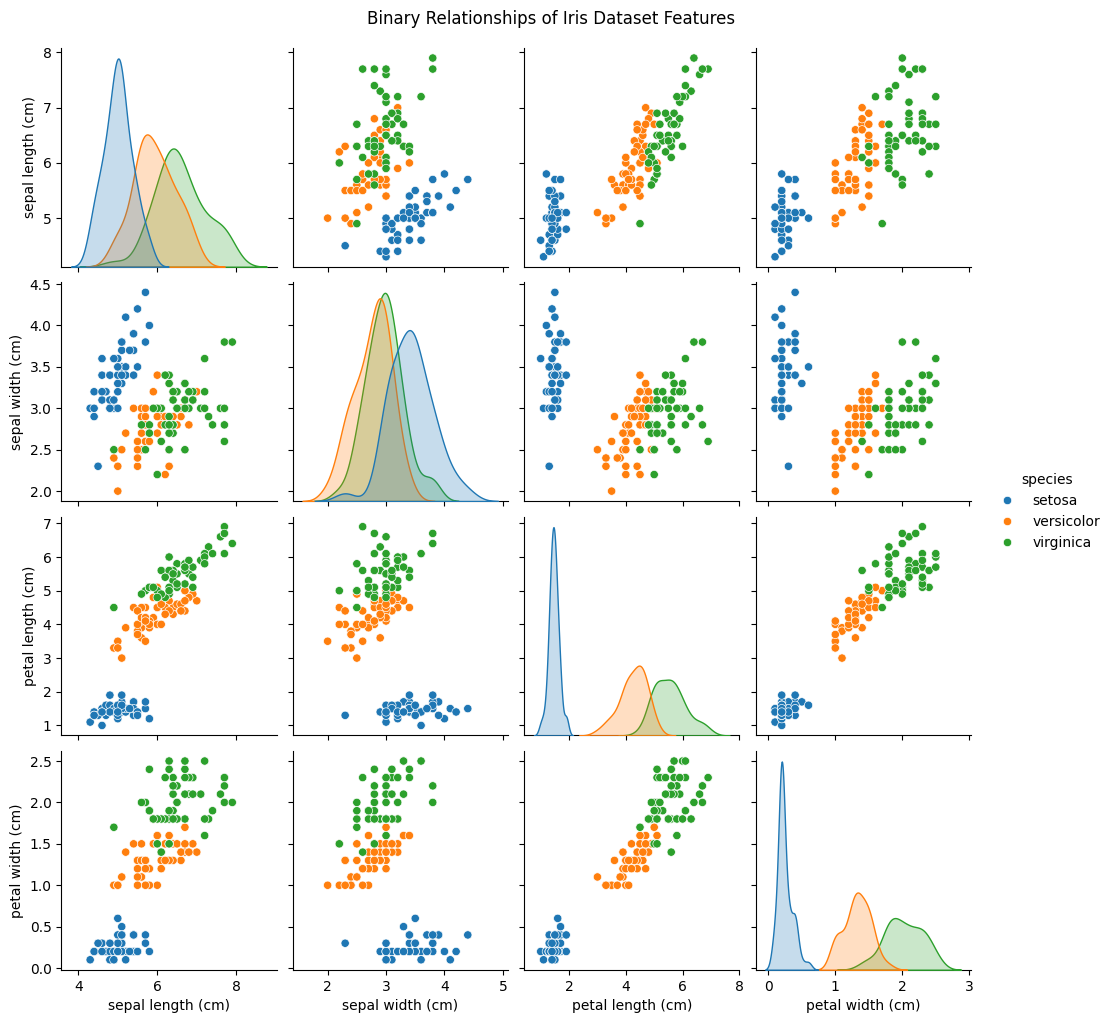

In [55]:
df_full_iris = pd.DataFrame(data=X_full, columns=iris.feature_names)
df_full_iris['species'] = iris.target_names[y_full]
sns.pairplot(df_full_iris, hue='species', diag_kind='kde')
plt.suptitle('Binary Relationships of Iris Dataset Features', y=1.02)
plt.show()

In [56]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [57]:
X_full = iris.data
y_full = iris.target

# Tek bir train/test split yapın (4 özellikli)
X_train_full, X_test_full, y_train, y_test = train_test_split(X_full, y_full, 
                                                              test_size=0.3, 
                                                              random_state=42, 
                                                              stratify=y_full)

X_train_2f = X_train_full[:, [2, 3]]
X_test_2f = X_test_full[:, [2, 3]]

X_full.shape




(150, 4)

In [58]:
def plot_decision_boundary(X, y, model, title):
    """
    Visualize the decision boundaries of a classifier.
    """
    # Set color maps and markers
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ['red', 'green', 'blue']

    # Set step size
    h = .02  # step size in the mesh

    # Find the min and max values of the features and leave some margin
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Create a mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Make predictions for each point in the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Reshape the result back to the grid shape
    Z = Z.reshape(xx.shape)

    # Plot the graph
    plt.figure(figsize=(10, 8))
    # Color the decision boundaries
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Draw the training points on top
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=iris.target_names[y],
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.legend(title='Species')
    plt.show()



In [59]:
class SingleLayerPerceptron:
    # ... (init parametreleri aynı kalabilir)
    def __init__(self, learning_rate=0.01, n_iters=1000, random_state=42):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.weights_ = None # Ağırlıkları burada None yapın
        self.errors_ = []
        # Ağırlık başlatmayı fit metoduna taşıyın veya fit'ten önce çağrılacak ayrı bir metoda

    # train_epoch, net_input, predict metodları aynı kalabilir.

    def fit(self, X, y, plot_every=None): # plot_every parametresini ekleyelim (OvR'dan gelebilir)
        """Fits the model to the training data."""
        
        # --- YENİ EKLENEN KISIM: Ağırlıkları burada başlatın ---
        rgen = np.random.RandomState(self.random_state)
        # self.weights_ ilk defa burada X'in boyutuna göre oluşturuluyor
        if self.weights_ is None: 
            self.weights_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1] + 1) 
        # --------------------------------------------------------

        self.errors_ = []
        for epoch in range(self.n_iters):
            self.train_epoch(X, y) # train_epoch'u çağırın
            
            # Eğer SLP_OvR içinden çağrılıyorsa ve plot_every verildiyse,
            # çizim OvR sınıfında yapılacak, burada değil.
            # Eğer tek başına SLP eğitiyorsanız çizimi buraya ekleyebilirsiniz.
            
        return self

    # train_epoch metodu (içeriği aynı)
    def train_epoch(self, X, y):
        """One epoch of training."""
        X_b = np.c_[np.ones((len(X), 1)), X]
        errors = 0
        for xi, target in zip(X_b, y):
            # predict(xi) çağrısı net_input(xi)'yi, o da np.dot(xi, self.weights_)'i çağıracak
            # Artık self.weights_ doğru boyutta (3,) olmalı
            update = self.learning_rate * (target - self.predict(xi)) 
            self.weights_ += update * xi
            errors += int(update != 0.0)
        self.errors_.append(errors)
        
    # net_input metodu (içeriği aynı)
    def net_input(self, X):
        """Calculates net input."""
        if X.ndim == 2:
             X_b = np.c_[np.ones((len(X), 1)), X]
             # np.dot(X_b [N, 3], self.weights_ [3,]) -> Çalışır
             return np.dot(X_b, self.weights_)
        else: # Single sample (xi, shape is (3,))
             # np.dot(X [3,], self.weights_ [3,]) -> Çalışır
             return np.dot(X, self.weights_)

    # predict metodu (içeriği aynı)
    def predict(self, X):
        """Makes a prediction (unit step function)."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

In [60]:
class SLP_OvR:
    # ... (init parametreleri aynı)
    def __init__(self, n_classes, learning_rate=0.01, n_iters=100, random_state=42): # n_iters'ı OvR için daha düşük tutabiliriz
        self.n_classes = n_classes
        self.learning_rate = learning_rate
        self.n_iters = n_iters # SLP için iterasyon sayısı
        self.random_state = random_state
        self.perceptrons_ = [
            # n_iters artık SLP için, OvR için değil
            SingleLayerPerceptron(learning_rate=self.learning_rate, n_iters=1, random_state=self.random_state + i) # Her birine farklı seed verelim
            for i in range(self.n_classes)
        ]

    # fit metodu aynı kalabilir, çünkü train_epoch çağrısı 
    # güncellenmiş SLP sınıfındaki predict/net_input'u doğru çalıştıracak.
    # Ancak çizim için plot_decision_boundary'yi çağırmadan önce
    # perceptronların ağırlıklarının başlatıldığından emin olmalıyız.
    # Bu yüzden ilk epoch'u döngü dışında yapmak daha güvenli olabilir VEYA
    # plot_decision_boundary'yi fit bittikten sonra çağırmak.
    # PDF her 5 epoch'ta istediği için mevcut yapı daha uygun.
    
    def fit(self, X, y, plot_every=5):
        """
        Train each perceptron in a one-vs-rest manner.
        """
        n_features = X.shape[1] # Özellik sayısını alalım
        
        # Ağırlıkları ilk başta doğru boyutta başlatalım (SLP.fit beklemeden)
        for p in self.perceptrons_:
            if p.weights_ is None:
                 rgen = np.random.RandomState(p.random_state)
                 p.weights_ = rgen.normal(loc=0.0, scale=0.01, size=n_features + 1)

        # Epoch döngüsü
        for epoch in range(self.n_iters): # Bu OvR için epoch sayısı olmalı
            for i in range(self.n_classes):
                y_ovr = np.where(y == i, 1, 0)
                # SLP'nin n_iters=1 olduğu için bu sadece bir epoch çalıştırır
                self.perceptrons_[i].train_epoch(X, y_ovr) 
            
            if (epoch + 1) % plot_every == 0:
                print(f"--- Epoch {epoch + 1} ---")
                # plot_decision_boundary artık çalışmalı
                plot_decision_boundary(X, y, self, 
                                       title=f'SLP Karar Sınırları - Epoch {epoch + 1}')
        return self

    # predict metodu aynı kalabilir
    def predict(self, X):
        """
        Return the class of the perceptron with the highest activation value as the prediction.
        """
        activations = np.array([p.net_input(X) for p in self.perceptrons_])
        return np.argmax(activations, axis=0)

--- Epoch 5 ---


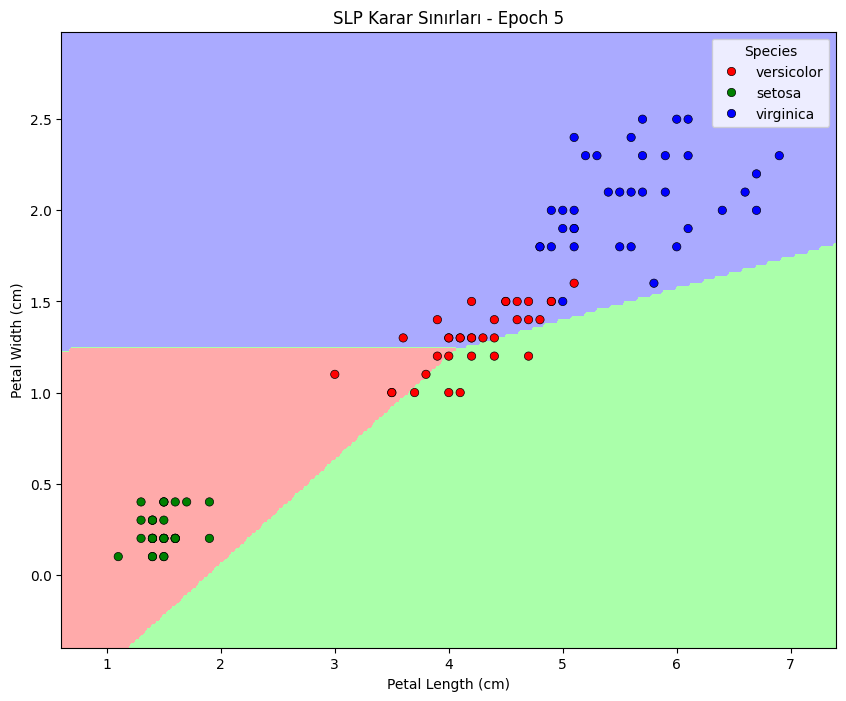

--- Epoch 10 ---


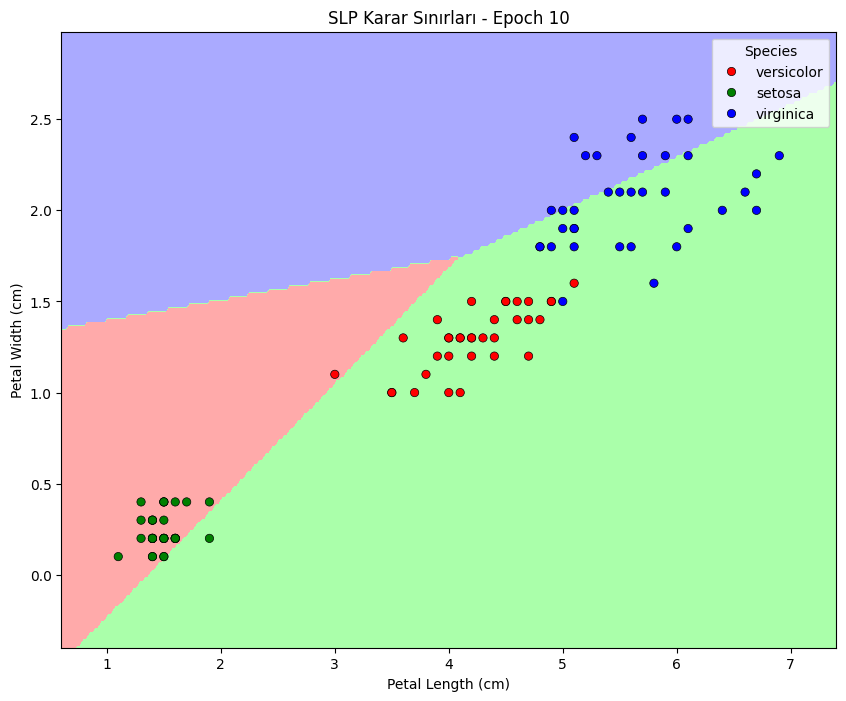

--- Epoch 15 ---


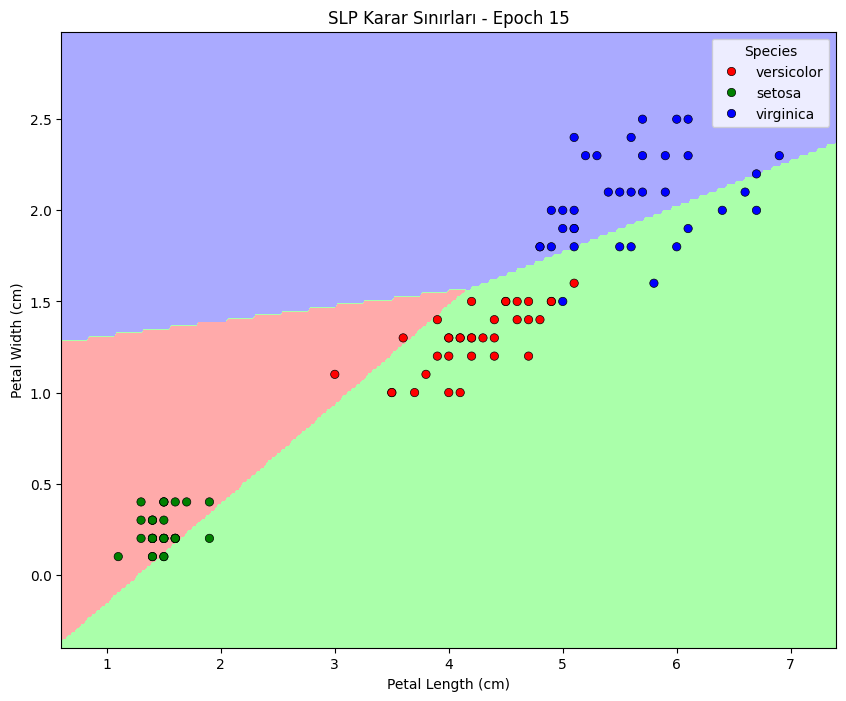

--- Epoch 20 ---


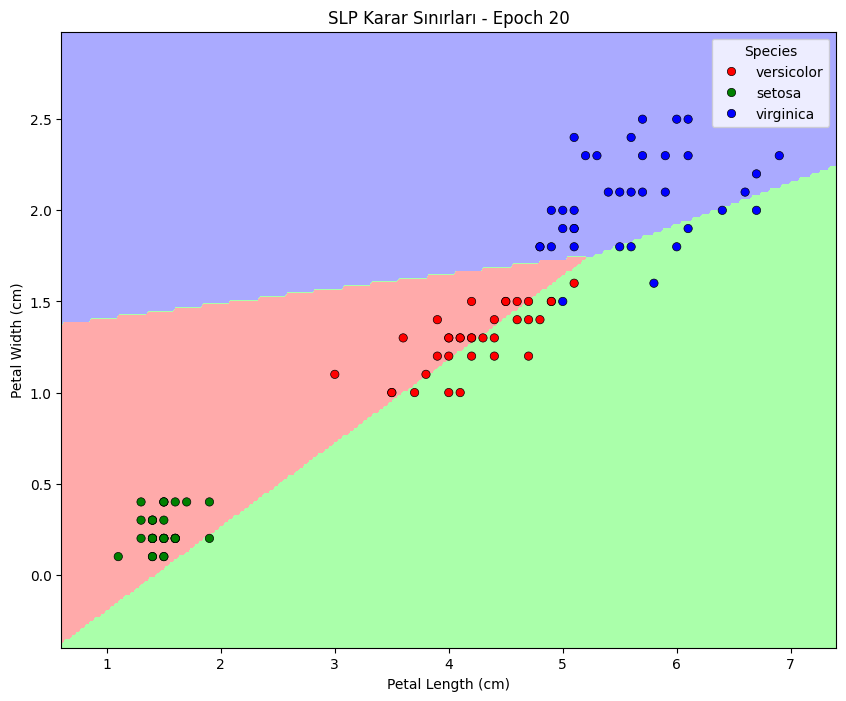

--- Epoch 25 ---


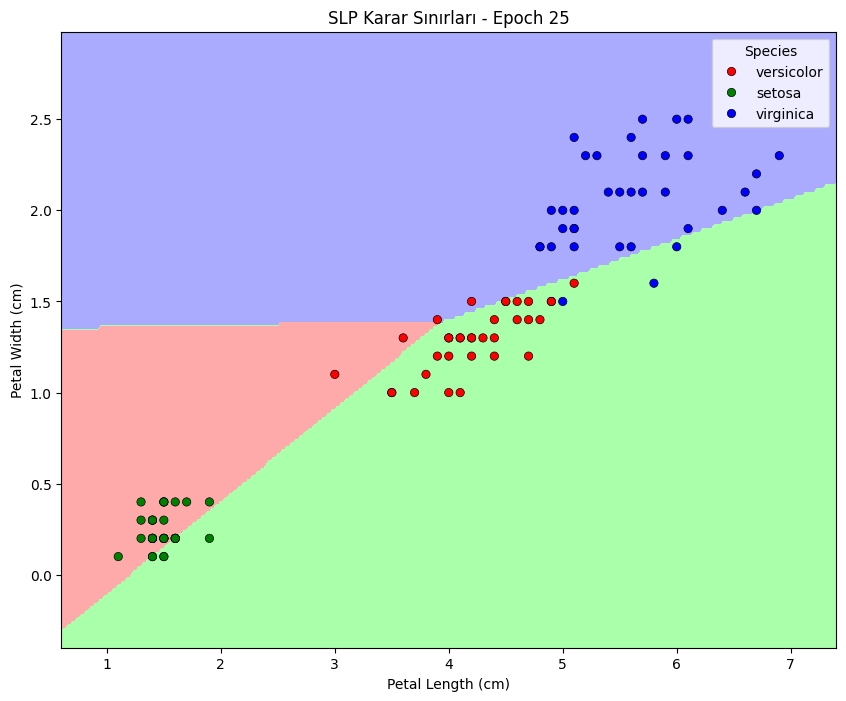

--- Epoch 30 ---


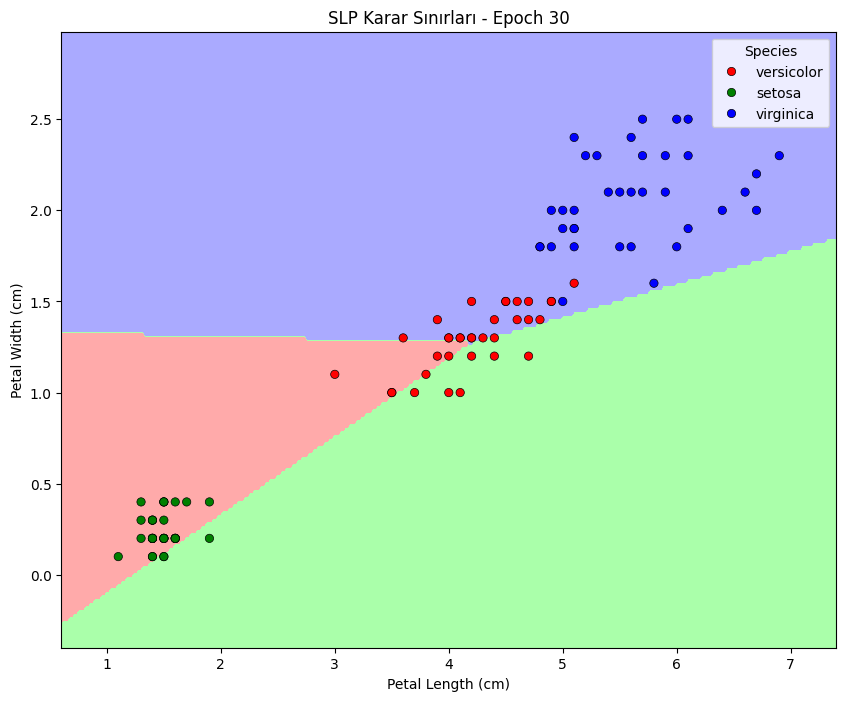

--- Epoch 35 ---


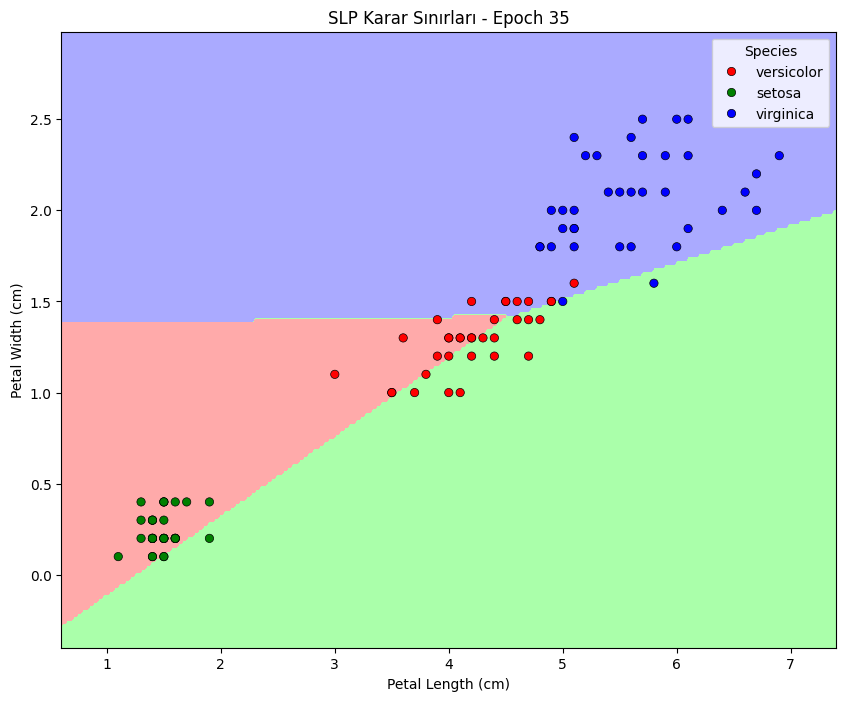

--- Epoch 40 ---


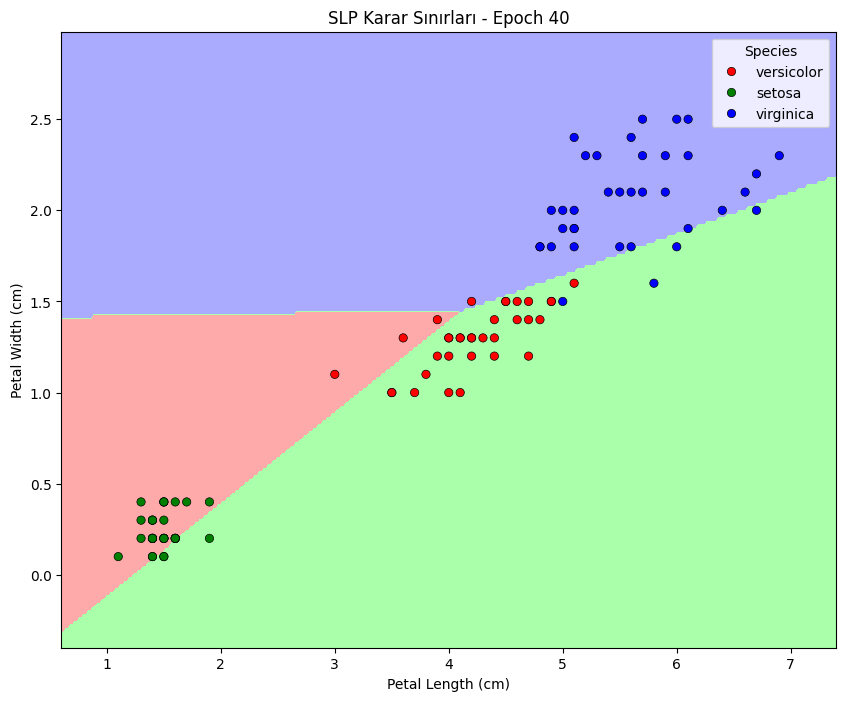

--- Epoch 45 ---


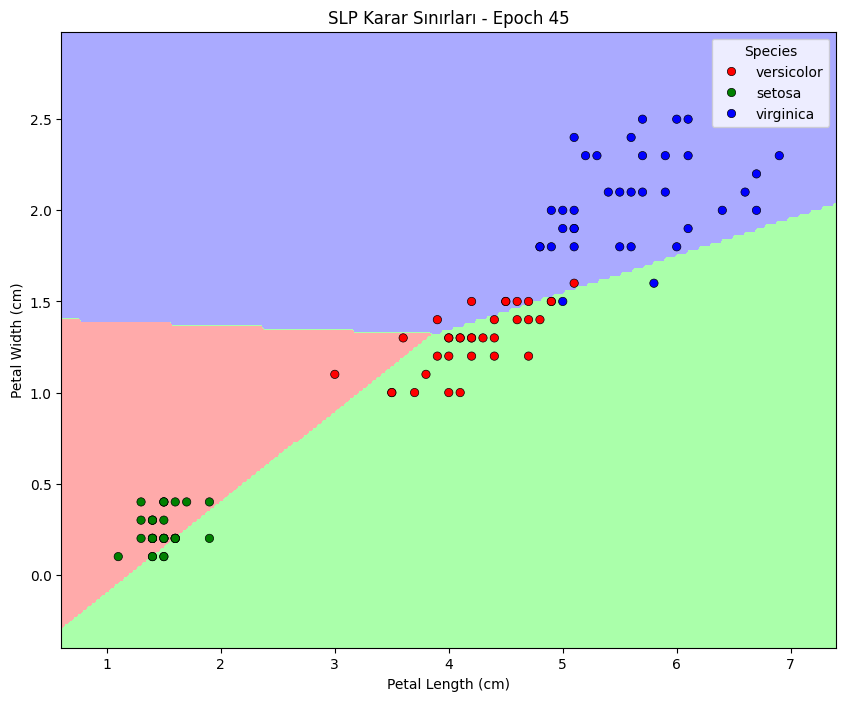

--- Epoch 50 ---


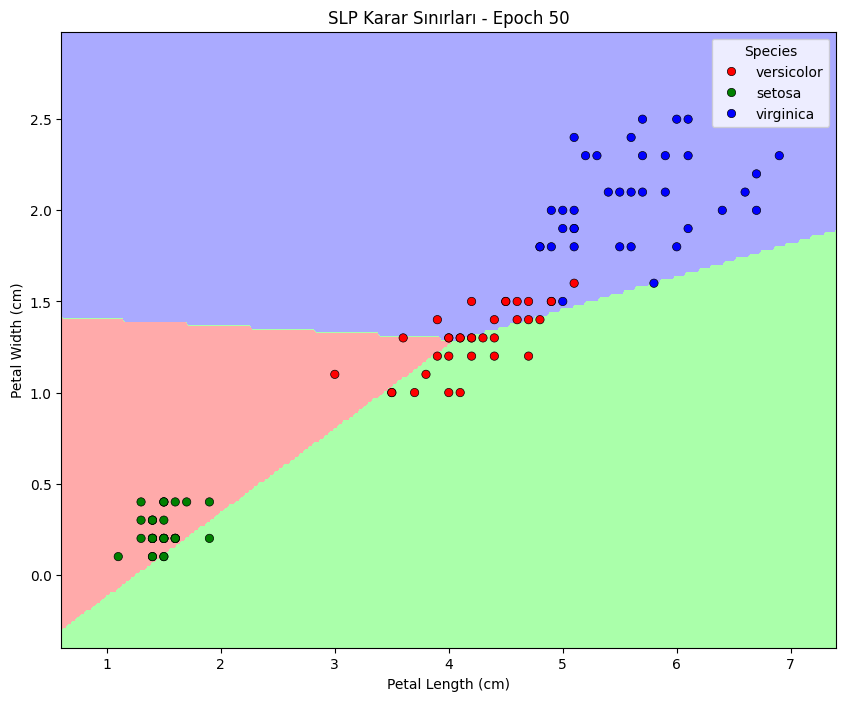

--- Epoch 55 ---


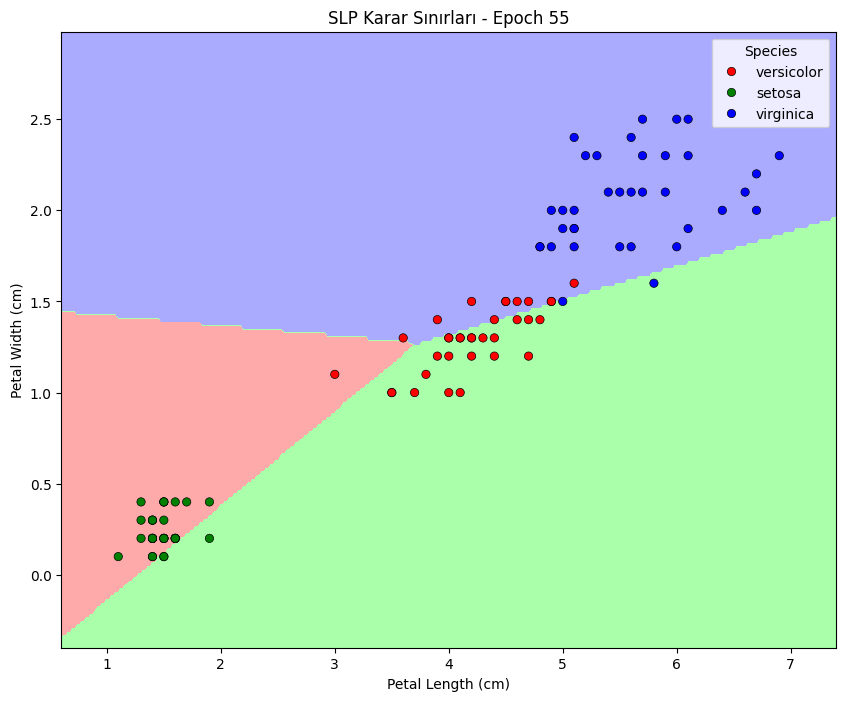

--- Epoch 60 ---


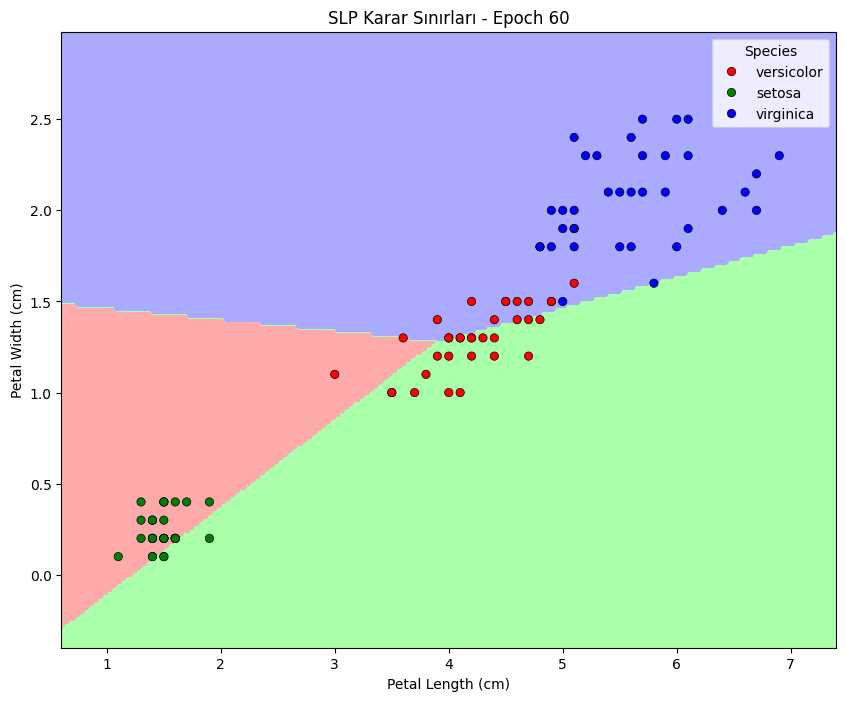

--- Epoch 65 ---


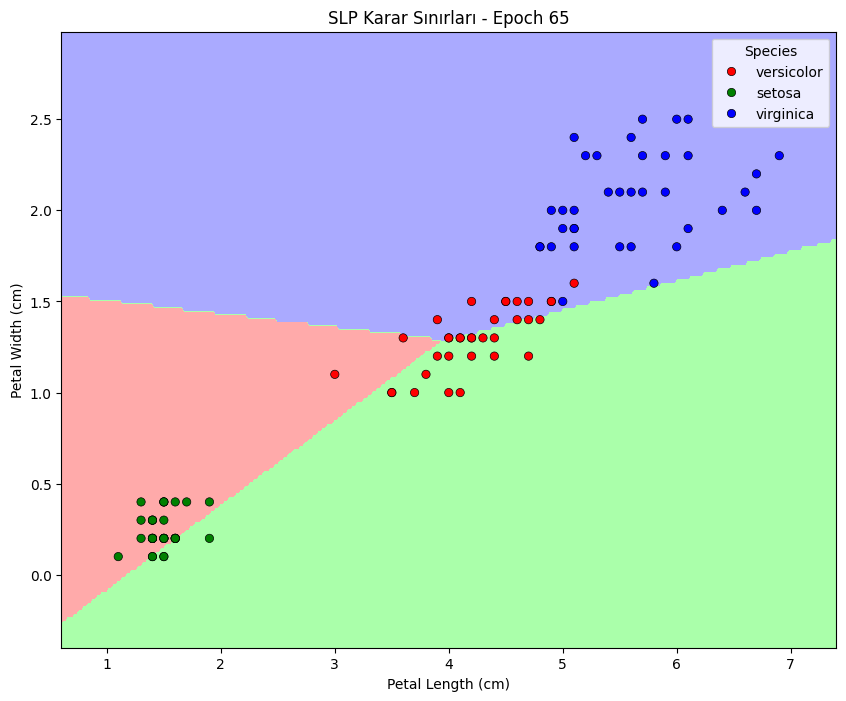

--- Epoch 70 ---


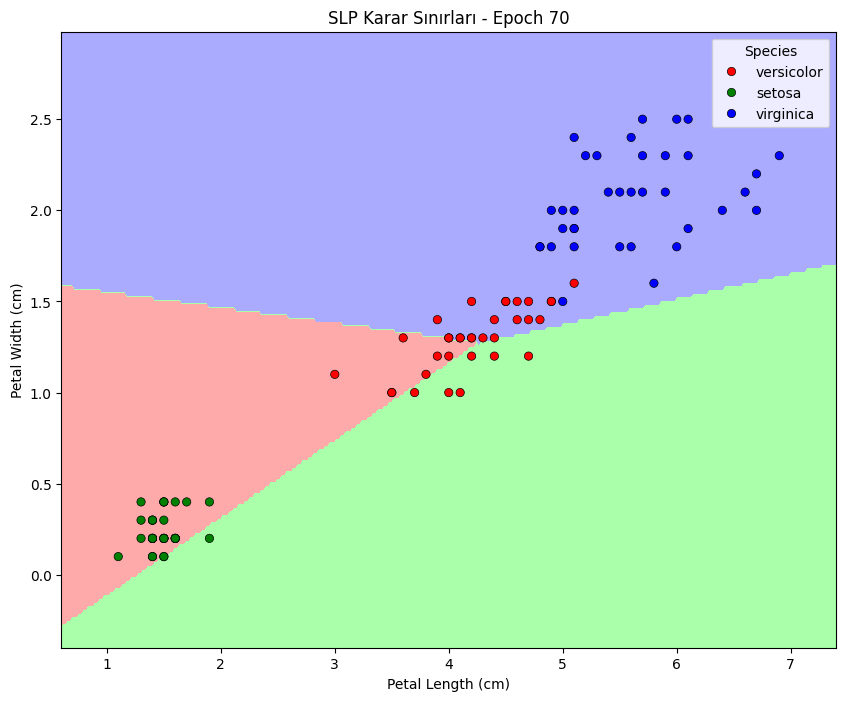

--- Epoch 75 ---


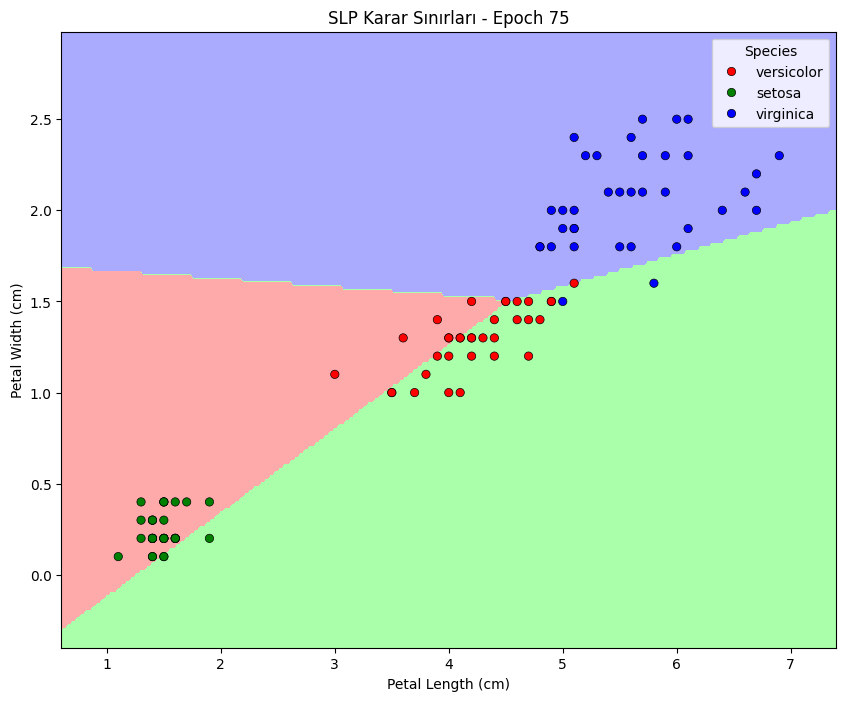

--- Epoch 80 ---


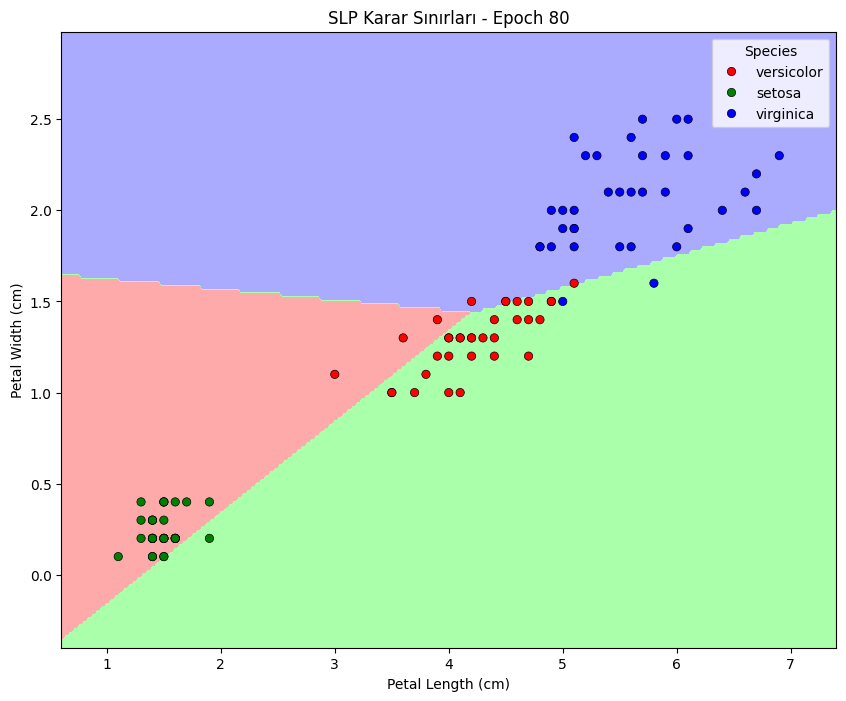

--- Epoch 85 ---


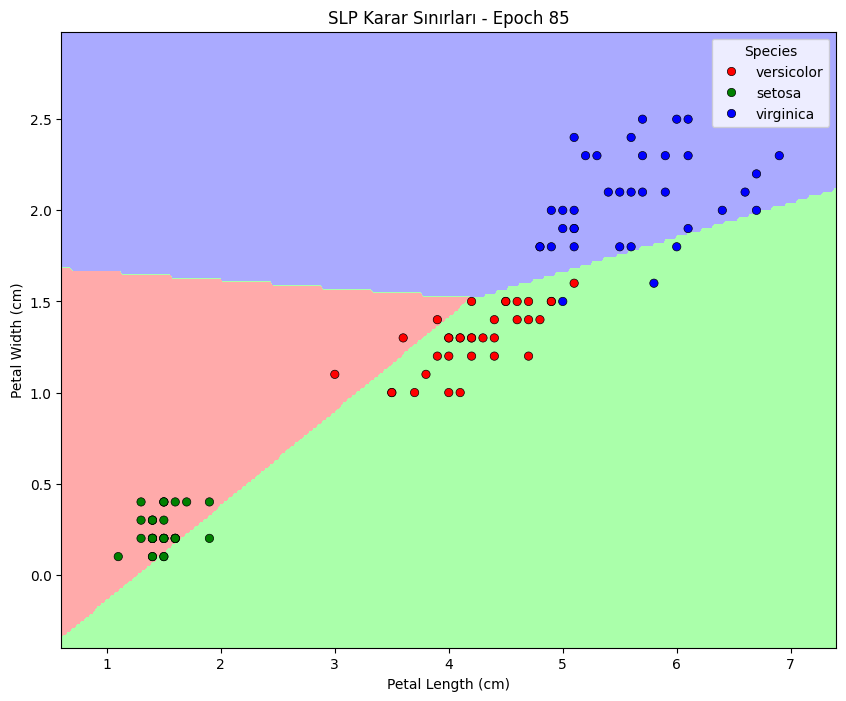

--- Epoch 90 ---


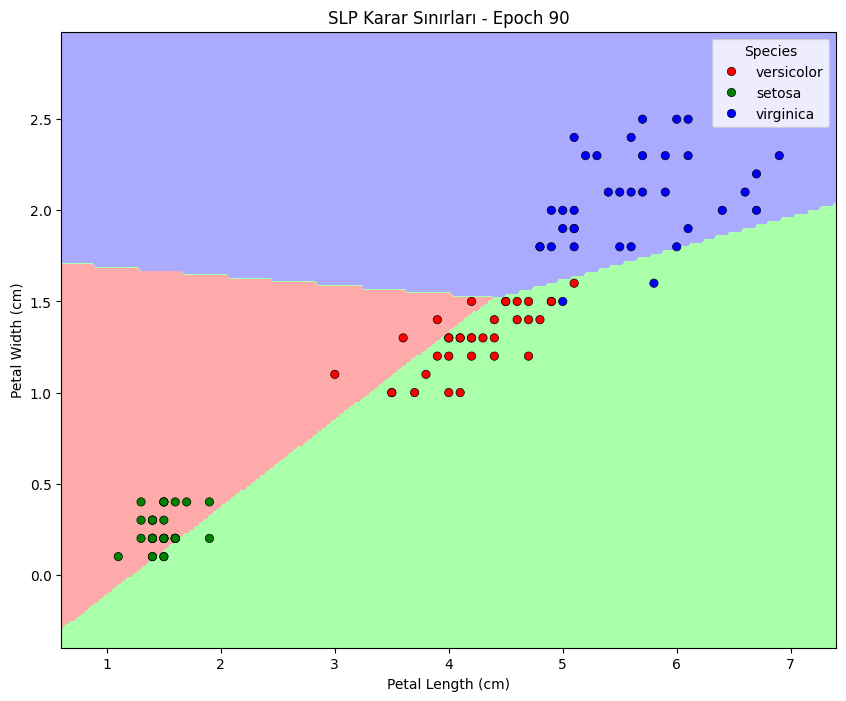

--- Epoch 95 ---


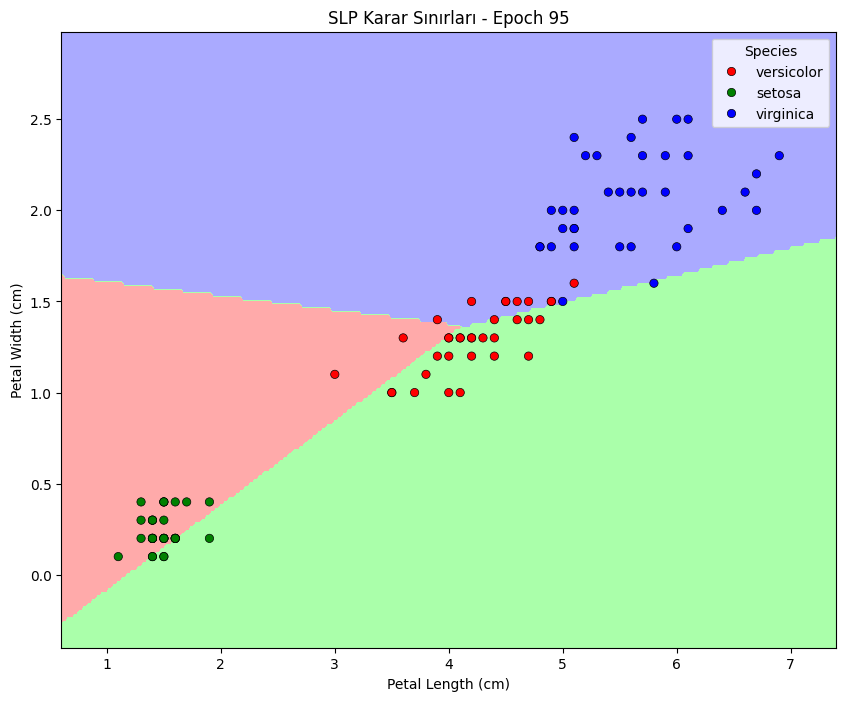

--- Epoch 100 ---


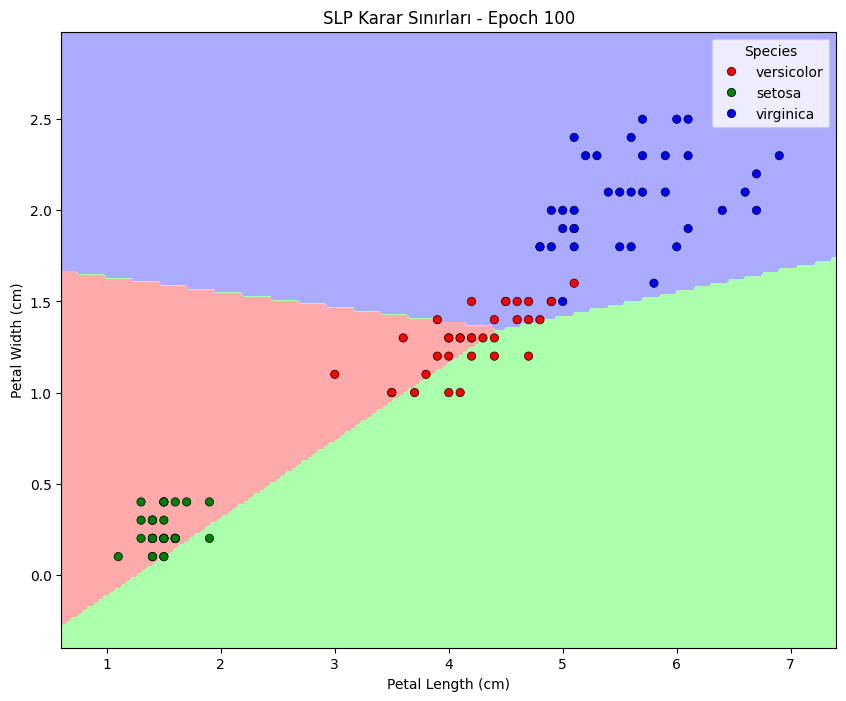

In [61]:
n_classes = len(np.unique(y_full))

# Create OvR model
slp_ovr_model = SLP_OvR(n_classes=n_classes, learning_rate=0.01, n_iters=100, random_state=42)

# Train the model
slp_ovr_model.fit(X_train_2f, y_train, plot_every=5)

In [62]:
y_pred = slp_ovr_model.predict(X_test_2f)

In [63]:
# evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Test Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred)) # [cite: 22]
print("\nConfusion Matrix:") # [cite: 22]
print(confusion_matrix(y_test, y_pred))


Model Test Accuracy: 0.71

Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        15
           1       0.75      0.20      0.32        15
           2       0.64      0.93      0.76        15

    accuracy                           0.71        45
   macro avg       0.73      0.71      0.65        45
weighted avg       0.73      0.71      0.65        45


Confusion Matrix:
[[15  0  0]
 [ 4  3  8]
 [ 0  1 14]]


In [64]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Veri Hazırlama (Aynı Split ve Seed Kullanılmalı!)
# ----------------------------------------------------------------------
iris = load_iris()
# !!! DİKKAT: EDA'dan sonra seçtiğiniz iki özelliği burada kullanın.
# Örneğin: Petal Length ve Petal Width için: X_full = iris.data[:, 2:4]
X_full = iris.data[:, 2:4] # Bu satırı kendi seçiminize göre değiştirin! 
y_full = iris.target

# Ödev gereği random state'i sabitleyin
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE) 

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.3, random_state=RANDOM_STATE, stratify=y_full
)

# Özellik Ölçeklendirme (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

NUM_CLASSES = len(np.unique(y_full))

# Tek Sıcak Kodlama (One-Hot Encoding) Fonksiyonu
def one_hot_encode(y, num_classes):
    """Etiketleri (0, 1, 2) One-Hot formatına dönüştürür."""
    return np.eye(num_classes)[y]

Y_train_ohe = one_hot_encode(y_train, NUM_CLASSES)
Y_test_ohe = one_hot_encode(y_test, NUM_CLASSES)


# ----------------------------------------------------------------------
# 2. Yardımcı Fonksiyonlar: Aktivasyonlar, Türevler, Kayıp
# ----------------------------------------------------------------------

def tanh(Z):
    """Gizli katman aktivasyonu."""
    return np.tanh(Z)

def tanh_derivative(A):
    """Tanh aktivasyonunun türevi (Geri yayılım için)."""
    return 1 - np.power(A, 2)

def softmax(Z):
    """Çıkış katmanı aktivasyonu (Olasılıklara dönüştürür)."""
    # Sayısal stabilite için Z'den max değerini çıkar
    exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

def cross_entropy_loss(A_out, Y_true):
    """Çok sınıflı sınıflandırma için kayıp fonksiyonu."""
    m = Y_true.shape[0]
    # Y_true'daki 1 olan yerlerdeki A_out logaritmasını toplar
    log_probs = -np.log(A_out[range(m), np.argmax(Y_true, axis=1)] + 1e-9)
    loss = np.sum(log_probs) / m
    return loss

In [65]:
# ----------------------------------------------------------------------
# 3. MLP Sınıfı Tanımlaması (Mini-Batch SGD ile Güncellendi)
# ----------------------------------------------------------------------

class MLPClassifierFromScratch:
    """
    Tek gizli katmanlı Çok Katmanlı Algılayıcı (MLP) sınıfı.
    Mini-Batch Stochastic Gradient Descent (SGD) ile eğitilir.
    """
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        
        # Xavier/Glorot Başlatma
        limit1 = np.sqrt(6 / (input_size + hidden_size))
        self.W1 = np.random.uniform(-limit1, limit1, (input_size, hidden_size))
        self.b1 = np.zeros((1, hidden_size))
        
        limit2 = np.sqrt(6 / (hidden_size + output_size))
        self.W2 = np.random.uniform(-limit2, limit2, (hidden_size, output_size))
        self.b2 = np.zeros((1, output_size))
        
    def forward(self, X):
        """İleri Yayılım hesaplaması (Giriş -> Çıkış)."""
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = tanh(self.Z1) # Tanh aktivasyonu
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = softmax(self.Z2) # Softmax aktivasyonu
        return self.A2
        
    def backward(self, X, Y_true, A2):
        """Geri Yayılım (Gradyan hesaplaması)."""
        m = X.shape[0] # <-- Bu artık mini-batch boyutu olacak
        
        dZ2 = A2 - Y_true
        self.dW2 = (self.A1.T @ dZ2) / m
        self.db2 = np.sum(dZ2, axis=0, keepdims=True) / m
        
        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * tanh_derivative(self.A1)
        
        self.dW1 = (X.T @ dZ1) / m
        self.db1 = np.sum(dZ1, axis=0, keepdims=True) / m
        
    def update_parameters(self):
        """Parametreleri (W ve b) öğrenme oranı kullanarak günceller."""
        self.W1 -= self.learning_rate * self.dW1
        self.W2 -= self.learning_rate * self.dW2
        self.b1 -= self.learning_rate * self.db1
        self.b2 -= self.learning_rate * self.db2
        
    # --------------------------------------------------
    # GÜNCELLENEN train METODU (MINI-BATCH SGD)
    # --------------------------------------------------
    def train(self, X, Y_true, X_val, Y_val, epochs, batch_size=32):
        """MLP modelini Mini-Batch SGD ile eğitir."""
        
        history = {'loss': [], 'val_loss': []}
        n_samples = X.shape[0]
        
        for i in range(epochs):
            
            # 1. Veriyi Karıştır (Shuffle)
            # X ve Y_true'nun eşleşmesini korumak için indeksleri karıştırıyoruz
            indices = np.arange(n_samples)
            np.random.shuffle(indices)
            X_shuffled = X[indices]
            Y_shuffled = Y_true[indices]
            
            # 2. Mini-Batch'ler Üzerinde Döngü
            for start_idx in range(0, n_samples, batch_size):
                # Mini-batch'i oluştur
                end_idx = min(start_idx + batch_size, n_samples)
                X_batch = X_shuffled[start_idx:end_idx]
                Y_batch = Y_shuffled[start_idx:end_idx]
                
                # 3. Mini-Batch üzerinde İleri/Geri/Güncelleme
                A2_batch = self.forward(X_batch)
                self.backward(X_batch, Y_batch, A2_batch)
                self.update_parameters()
            
            # 4. Epoch Sonu Kayıp (Loss) Hesaplanması (Tüm veri seti üzerinden)
            # Stabil bir 'history' grafiği için kaybı tüm veri üzerinden hesaplıyoruz
            A2_train_full = self.forward(X)
            loss = cross_entropy_loss(A2_train_full, Y_true)
            
            A2_val = self.forward(X_val)
            val_loss = cross_entropy_loss(A2_val, Y_val)
            
            history['loss'].append(loss)
            history['val_loss'].append(val_loss)
            
            # Her 5000 epoch'ta veya 10 rapordan birinde durumu yazdır
            if (i + 1) % max(1, (epochs // 10)) == 0 or (i + 1) == epochs:
                print(f"Epoch {i+1}/{epochs} - Train Loss: {loss:.4f}, Val Loss: {val_loss:.4f}")
                
        return history
    
    def predict(self, X):
        """Eğitilmiş model ile tahmin yapar ve sınıf etiketlerini döndürür."""
        A2 = self.forward(X)
        return np.argmax(A2, axis=1) # En yüksek olasılığa sahip sınıfın indeksi

--- MLP Eğitimi Başlıyor ---
Hyperparameters: LR=0.1, Hidden=10, Features=2
Epoch 2000/20000 - Train Loss: 0.0469, Val Loss: 0.1483
Epoch 4000/20000 - Train Loss: 0.0468, Val Loss: 0.1565
Epoch 6000/20000 - Train Loss: 0.0463, Val Loss: 0.1582
Epoch 8000/20000 - Train Loss: 0.0446, Val Loss: 0.1554
Epoch 10000/20000 - Train Loss: 0.0433, Val Loss: 0.1709
Epoch 12000/20000 - Train Loss: 0.0424, Val Loss: 0.1936
Epoch 14000/20000 - Train Loss: 0.0410, Val Loss: 0.1935
Epoch 16000/20000 - Train Loss: 0.0399, Val Loss: 0.2103
Epoch 18000/20000 - Train Loss: 0.0409, Val Loss: 0.2060
Epoch 20000/20000 - Train Loss: 0.0378, Val Loss: 0.2296

---------------------------------------------------
MLP (From Scratch) Final Test Accuracy: 0.9333
---------------------------------------------------


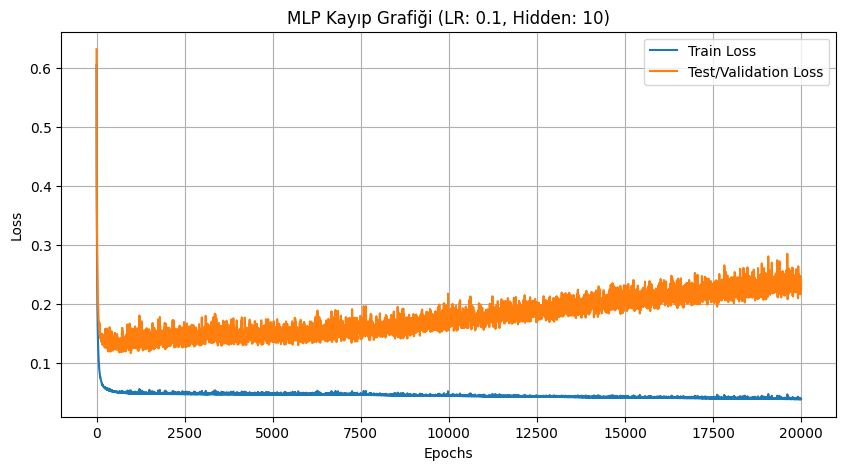

In [66]:
# ----------------------------------------------------------------------
# 4. Modeli Eğitme ve Değerlendirme
# ----------------------------------------------------------------------

# Model Hiperparametreleri
INPUT_SIZE = X_train_scaled.shape[1] 
HIDDEN_SIZE = 10                     # Deneme yapabileceğiniz nöron sayısı 
LEARNING_RATE = 0.1                  # Ödevin bonus kısmında bunu değiştirmeniz isteniyor
EPOCHS = 20000                       # Yüksek epoch sayısı yakınsama için önemlidir

# Modeli oluştur
mlp = MLPClassifierFromScratch(INPUT_SIZE, HIDDEN_SIZE, NUM_CLASSES, LEARNING_RATE)

print(f"--- MLP Eğitimi Başlıyor ---")
print(f"Hyperparameters: LR={LEARNING_RATE}, Hidden={HIDDEN_SIZE}, Features={INPUT_SIZE}")

# Modeli eğit (Test setini doğrulama kaybı için kullanıyoruz)
history = mlp.train(
    X_train_scaled, Y_train_ohe, 
    X_test_scaled, Y_test_ohe, 
    epochs=EPOCHS
)

# Test seti üzerinde tahmin yap
y_pred_test = mlp.predict(X_test_scaled)

# Doğruluğu (Accuracy) hesapla
accuracy = accuracy_score(y_test, y_pred_test)

print("\n---------------------------------------------------")
print(f"MLP (From Scratch) Final Test Accuracy: {accuracy:.4f}")
print("---------------------------------------------------")


# 5. Görselleştirme (Kaybın Azalması)
# ----------------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Test/Validation Loss')
plt.title(f'MLP Kayıp Grafiği (LR: {LEARNING_RATE}, Hidden: {HIDDEN_SIZE})')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# İpucu: Bonus kısım için farklı LEARNING_RATE değerleri (0.01, 0.1, 1.0 vb.)
# deneyerek en iyi sonucu raporlamanız gerekiyor.


--- MLP Sınıflandırma Raporu ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



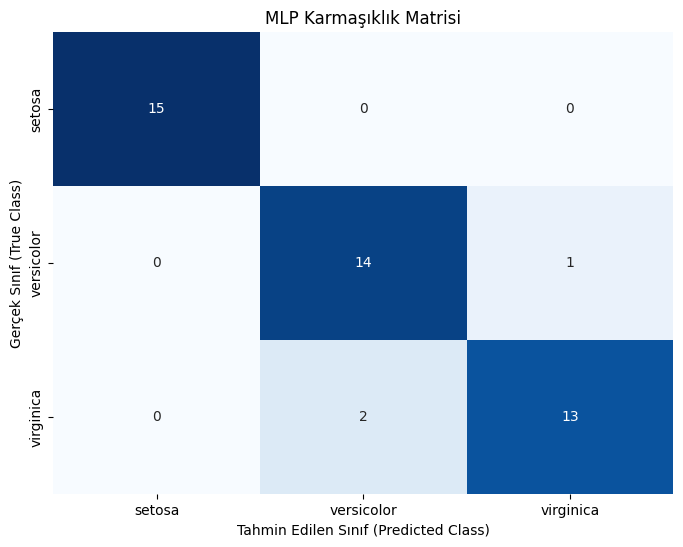

In [67]:
# Gerekli kütüphaneler (Zaten başta import edilmiş olmalı)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 6. Detaylı Değerlendirme ve Karmaşıklık Matrisi
# ----------------------------------------------------------------------

print("\n--- MLP Sınıflandırma Raporu ---")
# y_test: Gerçek etiketler, y_pred_test: Model tahminleri
print(classification_report(y_test, y_pred_test, target_names=iris.target_names))

# Karmaşıklık Matrisi (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True,          # Değerleri kutulara yazdır
    fmt='d',             # Tam sayı formatında yazdır
    cmap='Blues',        # Renk haritası
    cbar=False,          # Renk çubuğunu gizle
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title('MLP Karmaşıklık Matrisi')
plt.ylabel('Gerçek Sınıf (True Class)')
plt.xlabel('Tahmin Edilen Sınıf (Predicted Class)')
plt.show()

# Analiz Notu: Bu matris, modelinizin hangi sınıfları (Satırlar)
# diğer sınıflarla (Sütunlar) karıştırdığını açıkça gösterir.

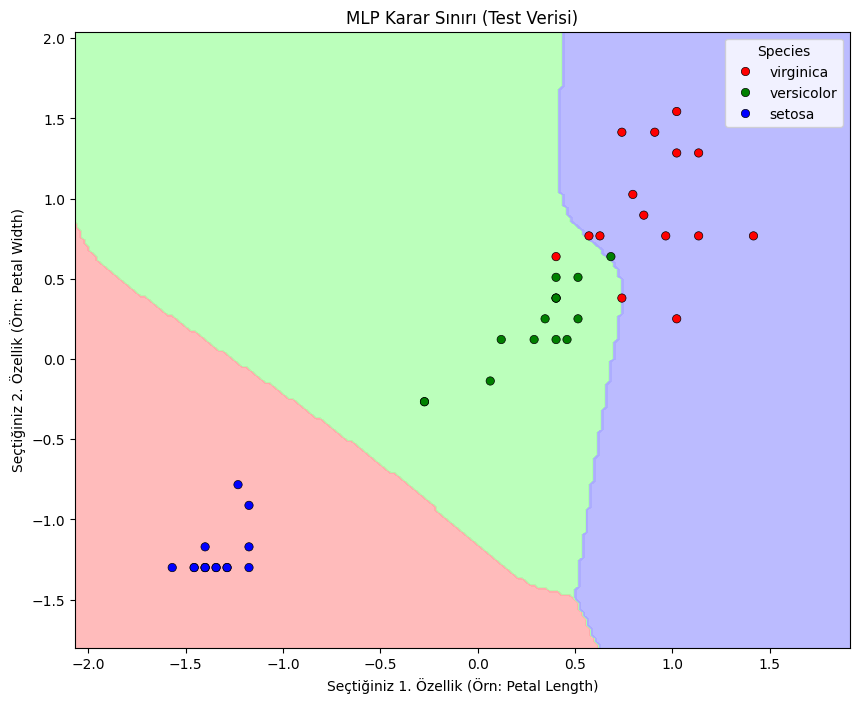

In [68]:
# Gerekli kütüphane (Zaten başta import edilmiş olmalı)
from matplotlib.colors import ListedColormap
import numpy as np

# ----------------------------------------------------------------------
# 7. Karar Sınırı (Decision Boundary) Fonksiyonu
# ----------------------------------------------------------------------

def plot_decision_boundary_mlp(X, y, model, title):
    """
    Eğitilmiş bir MLP'nin karar sınırlarını 2D uzayda görselleştirir.
    (X'in sadece 2 özellik içerdiği varsayılır).
    """
    # Renk haritalarını ve işaretçileri ayarla
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ['red', 'green', 'blue']

    h = .02  # Izgara adımı
    
    # Eksen sınırlarını belirle (biraz boşluk bırakarak)
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Izgara oluştur
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Izgara üzerindeki her nokta için tahmin yap
    # np.c_ ile ızgara noktaları (N, 2) boyutunda bir matrise dönüştürülür
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Tahmin sonuçlarını ızgara şekline geri getir
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(10, 8))
    
    # Karar sınırlarını renklendir
    plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

    # Gerçek eğitim/test noktalarını üzerine çiz
    sns.scatterplot(x=X[:, 0], y=X[:, 1], 
                    hue=iris.target_names[y],
                    palette=cmap_bold, 
                    alpha=1.0, 
                    edgecolor="black")
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    
    # !!! DİKKAT: Eksen etiketlerini seçtiğiniz 2 özelliğe göre güncelleyin.
    plt.xlabel('Seçtiğiniz 1. Özellik (Örn: Petal Length)') 
    plt.ylabel('Seçtiğiniz 2. Özellik (Örn: Petal Width)')
    
    plt.title(title)
    plt.legend(title='Species')
    plt.show()

# Eğitilmiş MLP modelinin karar sınırını görselleştirme
# !!! X_test_scaled, 2 özellikli veri olmalıdır.
plot_decision_boundary_mlp(
    X_test_scaled, 
    y_test, 
    mlp, # Eğitilmiş MLP modeliniz
    'MLP Karar Sınırı (Test Verisi)'
)

In [74]:
# Not: X_train, y_train, X_test, y_test'in 
# en başta (4 özellikli olarak) yüklendiğini varsayıyoruz.
# Part 2'deki X_train_2f'yi KULLANMIYORUZ.
print(f"Part 3 için kullanılacak X_train boyutu: {X_full.shape}")
print(f"Part 3 için kullanılacak y_train boyutu: {y_train.shape}")

Part 3 için kullanılacak X_train boyutu: (150, 2)
Part 3 için kullanılacak y_train boyutu: (105,)


In [70]:
#PIPELINE

# 1. Pipeline'ı Oluştur
# Adım 1: Veriyi ölçeklendir (StandardScaler)
# Adım 2: En iyi k özelliği seç (SelectKBest)
# Adım 3: Modeli uygula (Perceptron)
pipe_slp = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('model', Perceptron(random_state=42)) 
])

# 2. Parametre Izgarasını (Grid) Tanımla
# PDF'in istediği k={2,3,4} araması 'selector__k' ile yapılır
param_grid_slp = {
    'selector__k': [2, 3, 4], # PDF'te istenen özellik sayısı araması
    'model__eta0': [0.1, 0.05, 0.01], # Öğrenme oranı (eta0)
    'model__max_iter': [1000, 2000]   # Maksimum iterasyon
}

# 3. GridSearchCV'yi Kur ve Başlat
# cv=5 (5-katlı cross-validation), n_jobs=-1 (tüm CPU çekirdeklerini kullan)
grid_slp = GridSearchCV(
    pipe_slp, 
    param_grid=param_grid_slp, 
    cv=5, 
    n_jobs=-1,
    verbose=1 # Arama ilerlemesini göster
)

print("Scikit-learn Perceptron (SLP) için GridSearchCV başlıyor...")
grid_slp.fit(X_train_full, y_train) # 4 özellikli veri ile eğit

# 4. En İyi Sonuçları Göster
print("\n--- SLP (Perceptron) GridSearchCV Sonuçları ---")
print(f"En iyi Skor (Cross-Validation Accuracy): {grid_slp.best_score_:.4f}")
print("En iyi Parametreler:")
print(grid_slp.best_params_)

Scikit-learn Perceptron (SLP) için GridSearchCV başlıyor...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

--- SLP (Perceptron) GridSearchCV Sonuçları ---
En iyi Skor (Cross-Validation Accuracy): 0.8952
En iyi Parametreler:
{'model__eta0': 0.05, 'model__max_iter': 1000, 'selector__k': 4}


In [71]:
# ----------------------------------------------------------------------
# 3.2: Scikit-learn MLPClassifier (MLP) Pipeline
# ----------------------------------------------------------------------
import warnings
from sklearn.exceptions import ConvergenceWarning

# MLP'nin 'max_iter'a ulaşınca verdiği uyarıları gizle
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 1. Pipeline'ı Oluştur
pipe_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('model', MLPClassifier(random_state=42, early_stopping=True)) # early_stopping iyidir
])

# 2. Parametre Izgarasını Tanımla
param_grid_mlp = {
    'selector__k': [2, 3, 4], # PDF'te istenen özellik sayısı araması
    'model__solver': ['sgd'], # PDF'te 'sgd' istendi
    'model__hidden_layer_sizes': [(10,), (20,), (10, 5)], # Denemek için birkaç gizli katman yapısı
    'model__learning_rate_init': [0.1, 0.05, 0.01], # Öğrenme oranı
    'model__max_iter': [1500] 
}

# 3. GridSearchCV'yi Kur ve Başlat
grid_mlp = GridSearchCV(
    pipe_mlp, 
    param_grid=param_grid_mlp, 
    cv=5, 
    n_jobs=-1,
    verbose=1 
)

print("\nScikit-learn MLPClassifier için GridSearchCV başlıyor...")
grid_mlp.fit(X_train_full, y_train) # 4 özellikli veri ile eğit

# 4. En İyi Sonuçları Göster
print("\n--- MLP (MLPClassifier) GridSearchCV Sonuçları ---")
print(f"En iyi Skor (Cross-Validation Accuracy): {grid_mlp.best_score_:.4f}")
print("En iyi Parametreler:")
print(grid_mlp.best_params_)


Scikit-learn MLPClassifier için GridSearchCV başlıyor...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

--- MLP (MLPClassifier) GridSearchCV Sonuçları ---
En iyi Skor (Cross-Validation Accuracy): 0.9619
En iyi Parametreler:
{'model__hidden_layer_sizes': (20,), 'model__learning_rate_init': 0.1, 'model__max_iter': 1500, 'model__solver': 'sgd', 'selector__k': 2}


In [72]:
# ----------------------------------------------------------------------
# 1. ADIM: PART 3 (SKLEARN) MODELLERİNİN TEST DEĞERLENDİRMESİ
# ----------------------------------------------------------------------

print("="*50)
print("PART 3 - SKLEARN MODELLERİ TEST SETİ DEĞERLENDİRMESİ")
print("="*50)

# 1. En iyi SLP (Perceptron) modelini al ve X_test üzerinde tahmin yap
# grid_slp değişkeninin bir önceki hücrede eğitildiğini varsayıyoruz
best_slp_model = grid_slp.best_estimator_
y_pred_slp_sklearn = best_slp_model.predict(X_test_full) # Orijinal X_test (4 özellikli)

print("\n--- 1. SKLEARN PERCEPTRON (EN İYİ MODEL) TEST RAPORU ---")
print(f"En iyi parametreler: {grid_slp.best_params_}")
print(classification_report(y_test, y_pred_slp_sklearn, target_names=iris.target_names))
print("Konfüzyon Matrisi (Confusion Matrix):")
cm_slp = confusion_matrix(y_test, y_pred_slp_sklearn)
print(cm_slp)

# 2. En iyi MLP (MLPClassifier) modelini al ve X_test üzerinde tahmin yap
# grid_mlp değişkeninin bir önceki hücrede eğitildiğini varsayıyoruz
best_mlp_model_sklearn = grid_mlp.best_estimator_
y_pred_mlp_sklearn = best_mlp_model_sklearn.predict(X_test_full) # Orijinal X_test (4 özellikli)

print("\n--- 2. SKLEARN MLPCLASSIFIER (EN İYİ MODEL) TEST RAPORU ---")
print(f"En iyi parametreler: {grid_mlp.best_params_}")
print(classification_report(y_test, y_pred_mlp_sklearn, target_names=iris.target_names))
print("Konfüzyon Matrisi (Confusion Matrix):")
cm_mlp = confusion_matrix(y_test, y_pred_mlp_sklearn)
print(cm_mlp)

PART 3 - SKLEARN MODELLERİ TEST SETİ DEĞERLENDİRMESİ

--- 1. SKLEARN PERCEPTRON (EN İYİ MODEL) TEST RAPORU ---
En iyi parametreler: {'model__eta0': 0.05, 'model__max_iter': 1000, 'selector__k': 4}
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.65      0.87      0.74        15
   virginica       1.00      0.53      0.70        15

    accuracy                           0.80        45
   macro avg       0.84      0.80      0.79        45
weighted avg       0.84      0.80      0.79        45

Konfüzyon Matrisi (Confusion Matrix):
[[15  0  0]
 [ 2 13  0]
 [ 0  7  8]]

--- 2. SKLEARN MLPCLASSIFIER (EN İYİ MODEL) TEST RAPORU ---
En iyi parametreler: {'model__hidden_layer_sizes': (20,), 'model__learning_rate_init': 0.1, 'model__max_iter': 1500, 'model__solver': 'sgd', 'selector__k': 2}
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor      

In [73]:
# ----------------------------------------------------------------------
# 2. ADIM: PART 2 (SIFIRDAN) MODELLERİN TEST DEĞERLENDİRMESİ
# ----------------------------------------------------------------------

print("\n" + "="*50)
print("PART 2 - 'SIFIRDAN' (FROM-SCRATCH) MODELLERİN TEST DEĞERLENDİRMESİ")
print("="*50)

# DİKKAT: Sıfırdan modeller 2 özellikli veri (X_test_2f) üzerinde eğitildi.
# Bu yüzden X_test_2f üzerinde test edilmeliler.
# y_test ise her zaman orijinal 1D etiketlerdir.

# 1. Sıfırdan SLP (SLP_OvR) modelinin değerlendirilmesi
# 'slp_ovr' modelinin Cell 9'da eğitildiğini varsayıyoruz
y_pred_slp_scratch = slp_ovr_model.predict(X_test_2f)

print("\n--- 1. 'SIFIRDAN' SLP (SLP_OvR) TEST RAPORU ---")
print(classification_report(y_test, y_pred_slp_scratch, target_names=iris.target_names))
print("Konfüzyon Matrisi (Confusion Matrix):")
cm_slp_scratch = confusion_matrix(y_test, y_pred_slp_scratch)
print(cm_slp_scratch)


# 2. Sıfırdan MLP modelinin değerlendirilmesi
# 'mlp_ovr' modelinin Cell 11'de (veya Yöntem 1'de) eğitildiğini varsayıyoruz
# EĞER YÖNTEM 1'i (LR ARAMASI) YAPTIYSANIZ:
# aşağıdaki satırı 'best_mlp_model.predict(X_test_2f)' ile değiştirin
# -----------------------------------------------------------------
# EĞER YÖNTEM 1'i YAPMADIYSANIZ (Cell 11'deki orijinal model):
# Bu modelin 'predict' metodu (MLP_OvR) one-hot etiket döndürebilir, argmax almalıyız.
# VEYA en son konuştuğumuz MLPClassifierFromScratch'i kullandıysanız:
# y_pred_mlp_scratch = mlp_model.predict(X_test_2f) 
# (Lütfen 'mlp_ovr' veya 'mlp_model' hangisini kullandıysanız ona göre düzenleyin)
#mlp = MLPClassifierFromScratch(INPUT_SIZE, HIDDEN_SIZE, NUM_CLASSES, LEARNING_RATE)

try:
    # Bu, 'MLPClassifierFromScratch' (Adım 2) veya 'SLP_OvR' (Cell 11) için çalışır
    y_pred_mlp_scratch = mlp.predict(X_test_2f)
    
except AttributeError:
    # Eğer 'MLPClassifierFromScratch' (Adım 2) için LR araması yaptıysanız
    # ve değişken adınız 'best_mlp_model' ise:
    # y_pred_mlp_scratch = best_mlp_model.predict(X_test_2f)
    print("HATA: 'mlp_ovr' değişkeni bulunamadı. Lütfen eğitilmiş sıfırdan MLP")
    print("modelinizin değişken adını (örn: 'best_mlp_model') koda girin.")
    y_pred_mlp_scratch = y_pred_slp_scratch # Geçici olarak hatayı engelle

# 'MLP_OvR' (Cell 11) modeli OvR kullandığı için çıktısı (112, 3) olabilir,
# 'MLPClassifierFromScratch' ise (112,) döndürür. Emin olmak için:
if y_pred_mlp_scratch.ndim > 1:
    y_pred_mlp_scratch = np.argmax(y_pred_mlp_scratch, axis=1)


print("\n--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST RAPORU ---")
print(classification_report(y_test, y_pred_mlp_scratch, target_names=iris.target_names))
print("Konfüzyon Matrisi (Confusion Matrix):")
cm_mlp_scratch = confusion_matrix(y_test, y_pred_mlp_scratch)
print(cm_mlp_scratch)


PART 2 - 'SIFIRDAN' (FROM-SCRATCH) MODELLERİN TEST DEĞERLENDİRMESİ

--- 1. 'SIFIRDAN' SLP (SLP_OvR) TEST RAPORU ---
              precision    recall  f1-score   support

      setosa       0.79      1.00      0.88        15
  versicolor       0.75      0.20      0.32        15
   virginica       0.64      0.93      0.76        15

    accuracy                           0.71        45
   macro avg       0.73      0.71      0.65        45
weighted avg       0.73      0.71      0.65        45

Konfüzyon Matrisi (Confusion Matrix):
[[15  0  0]
 [ 4  3  8]
 [ 0  1 14]]

--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST RAPORU ---
              precision    recall  f1-score   support

      setosa       0.00      0.00      0.00        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.33      1.00      0.50        15

    accuracy                           0.33        45
   macro avg       0.11      0.33      0.17        45
weighted avg       0.11  

/home/deniz/Desktop/Nlp/venv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/deniz/Desktop/Nlp/venv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/deniz/Desktop/Nlp/venv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 